# Python 刷题函数可视化

配套文档《Python 刷题函数从零讲解.md》的**交互版**：章节顺序相同，每个重要函数都配一个可以直接运行、会打印中间状态的代码单元，部分地方用 matplotlib 画图帮助理解。

- 数据来源：用 `ast` 对 **灵茶山艾府（灵神，Python 3）** 和 **yiduobo（Python 2 风格）** 共 6165 篇 LeetCode 题解做的函数使用普查。普查结果已直接嵌入下面的单元格，不依赖外部文件。
- 运行环境：Python 3.10+（`pairwise`、`bisect` 的 `key=`、`int.bit_count` 需要 3.10）。`sortedcontainers` 不是标准库，没装时相应单元会提示跳过。
- 阅读方式：从上到下依次运行（Kernel → Restart & Run All）。

目录：0 普查数据 · 1 内置函数 · 2 容器方法 · 3 collections · 4 heapq · 5 bisect · 6 itertools · 7 functools · 8 math / 位运算 · 9 语法特性 · 10 Python 2 vs 3 · 11 速查

In [1]:
# 公共设置：中文字体 + 配色（灵神 = 蓝，yiduobo = 橙）
import warnings, logging
warnings.filterwarnings("ignore")
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
import matplotlib
import matplotlib.pyplot as plt
plt.rcParams.update({
    "font.sans-serif": ["Noto Sans CJK SC", "Source Han Sans SC", "PingFang SC", "Microsoft YaHei",
                        "SimHei", "WenQuanYi Micro Hei", "Arial Unicode MS", "DejaVu Sans"],
    "axes.unicode_minus": False,
    "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
})
C_LING, C_YI, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#8a8984"
print("matplotlib", matplotlib.__version__)

matplotlib 3.11.2


## 0. 普查数据（已嵌入）

每行：`[名称, 类别, 灵神篇数, yiduobo篇数, 灵神出现次数, yiduobo出现次数]`。"篇数" = 出现该函数的题解文件数。别名已合并（`heappush` 与 `heapq.heappush` 记为同一个）。

In [2]:
STATS = {"灵茶山艾府": {"files": 2540, "blocks": 4006, "blocks_ok": 3983, "files_parsed": 2277, "blocks_failed": 5, "files_no_code": 257, "blocks_text_skipped": 18, "files_failed": 6}, "yiduobo": {"files": 3625, "blocks": 3637, "blocks_ok": 3622, "files_parsed": 3624, "blocks_fixed": 15, "files_no_code": 1}}
FUNC = [["len", "builtin", 1268, 2104, 3053, 4208], ["range", "builtin", 1077, 1835, 3288, 4561], [".append", "method", 556, 1374, 1306, 2952], ["max", "builtin", 660, 743, 1697, 1361], ["enumerate", "builtin", 749, 482, 1469, 552], ["min", "builtin", 483, 424, 1045, 675], ["set", "builtin", 176, 465, 270, 675], [".add", "method", 114, 377, 200, 685], ["sum", "builtin", 320, 163, 546, 190], ["sorted", "builtin", 146, 327, 222, 387], ["int", "builtin", 235, 209, 401, 461], [".get", "method", 36, 388, 54, 757], [".pop", "method", 148, 257, 238, 382], [".sort", "method", 242, 146, 374, 172], ["list", "builtin", 235, 86, 379, 98], [".join", "method", 116, 180, 161, 226], ["zip", "builtin", 197, 80, 313, 87], ["math.inf", "mod", 272, 0, 746, 0], ["abs", "builtin", 97, 141, 235, 304], ["ord", "builtin", 102, 124, 357, 242], ["functools.cache", "mod", 223, 0, 276, 0], ["str", "builtin", 83, 116, 147, 222], ["heapq.heappop", "mod", 56, 134, 84, 210], ["heapq.heappush", "mod", 57, 131, 87, 281], [".values", "method", 89, 97, 129, 106], ["collections.defaultdict", "mod", 172, 0, 265, 0], ["collections.Counter", "mod", 139, 30, 228, 37], [".items", "method", 79, 70, 122, 86], ["bisect.bisect_left", "mod", 144, 0, 222, 0], [".reverse", "method", 20, 114, 23, 119], [".bit_length", "method", 109, 0, 177, 0], ["map", "builtin", 104, 0, 183, 0], ["itertools.pairwise", "mod", 86, 0, 121, 0], ["collections.deque", "mod", 64, 21, 91, 28], [".split", "method", 17, 68, 21, 90], [".popleft", "method", 63, 21, 93, 31], ["itertools.accumulate", "mod", 83, 0, 126, 0], ["chr", "builtin", 9, 69, 12, 102], [".extend", "method", 20, 47, 29, 66], [".remove", "method", 16, 50, 25, 70], [".copy", "method", 39, 17, 65, 20], [".bit_count", "method", 50, 0, 88, 0], ["all", "builtin", 44, 0, 52, 0], ["pow", "builtin", 43, 0, 77, 0], ["divmod", "builtin", 42, 0, 53, 0], ["bisect.bisect_right", "mod", 36, 0, 51, 0], ["heapq.heapify", "mod", 20, 16, 29, 16], [".count", "method", 35, 0, 61, 0], ["math.isqrt", "mod", 34, 0, 56, 0], ["math.sqrt", "mod", 7, 27, 13, 37], [".keys", "method", 3, 31, 5, 41], ["math.gcd", "mod", 33, 0, 86, 0], ["reversed", "builtin", 26, 0, 37, 0], ["sortedcontainers.SortedList", "mod", 26, 0, 36, 0], ["print", "builtin", 9, 17, 10, 22], ["string.ascii_lowercase", "mod", 24, 0, 46, 0], ["tuple", "builtin", 14, 10, 22, 23], ["any", "builtin", 24, 0, 30, 0], ["itertools.count", "mod", 23, 0, 33, 0], ["math.comb", "mod", 22, 0, 40, 0], ["bin", "builtin", 10, 11, 14, 17], ["functools.reduce", "mod", 20, 0, 29, 0], ["random.randint", "mod", 6, 14, 8, 17], [".cache_clear", "method", 19, 0, 21, 0], [".find", "method", 6, 12, 7, 16], [".index", "method", 14, 2, 25, 2], [".replace", "method", 8, 8, 15, 10], [".clear", "method", 14, 1, 20, 1], [".bisect_left", "method", 15, 0, 17, 0], ["operator.xor", "mod", 13, 0, 21, 0], [".isdigit", "method", 9, 4, 14, 5], [".update", "method", 4, 8, 7, 9], [".discard", "method", 12, 0, 13, 0], ["heapq.heapreplace", "mod", 11, 0, 16, 0], ["math.lcm", "mod", 10, 0, 23, 0], ["dict", "builtin", 10, 0, 15, 0], [".appendleft", "method", 9, 1, 13, 2], [".lower", "method", 9, 1, 13, 2], ["next", "builtin", 9, 0, 11, 0], [".zfill", "method", 9, 0, 10, 0], ["object", "builtin", 8, 0, 26, 0], ["math.ceil", "mod", 7, 1, 14, 2], ["itertools.permutations", "mod", 8, 0, 10, 0], ["heapq.heapreplace_max", "mod", 8, 0, 9, 0], ["heapq.nlargest", "mod", 8, 0, 9, 0], ["heapq.heapify_max", "mod", 8, 0, 8, 0], ["float", "builtin", 1, 6, 2, 14], ["numpy.array", "mod", 7, 0, 15, 0], ["copy.deepcopy", "mod", 0, 7, 0, 11], ["heapq.heappushpop", "mod", 7, 0, 10, 0], ["itertools.groupby", "mod", 7, 0, 10, 0], ["operator.or_", "mod", 7, 0, 10, 0], ["heapq.heappush_max", "mod", 7, 0, 7, 0], [".release", "method", 0, 6, 0, 22], [".acquire", "method", 0, 6, 0, 17], ["threading.Semaphore", "mod", 0, 6, 0, 14], ["itertools.combinations", "mod", 6, 0, 7, 0], [".matrix_power", "method", 6, 0, 6, 0], [".rstrip", "method", 6, 0, 6, 0], ["numpy.linalg", "mod", 6, 0, 6, 0], [".bisect_right", "method", 5, 0, 6, 0], [".rfind", "method", 4, 1, 5, 1], [".islower", "method", 5, 0, 5, 0], ["math.floor", "mod", 3, 1, 6, 4], ["math.pi", "mod", 0, 4, 0, 10], [".isalpha", "method", 4, 0, 7, 0], ["numpy.ones", "mod", 4, 0, 7, 0], ["numpy.zeros", "mod", 4, 0, 7, 0], [".isupper", "method", 4, 0, 6, 0], ["iter", "builtin", 4, 0, 4, 0], [".startswith", "method", 3, 1, 3, 1], ["heapq.heappop_max", "mod", 4, 0, 4, 0], [".put", "method", 0, 3, 0, 9], ["random.randrange", "mod", 3, 0, 5, 0], [".popitem", "method", 3, 0, 4, 0], ["heapq.nsmallest", "mod", 3, 0, 4, 0], ["itertools.chain", "mod", 3, 0, 4, 0], ["datetime.datetime", "mod", 3, 0, 3, 0], ["functools.cmp_to_key", "mod", 3, 0, 3, 0], ["math.cbrt", "mod", 3, 0, 3, 0]]
SYN = [["增量赋值 +=", "syn", 1370, 2424], ["docstring 类型注释 :type", "py2", 0, 3622], ["class X(object)", "py2", 1, 3618], ["类型注解", "syn", 2276, 0], ["and/or 短路", "syn", 800, 1457], ["for 中解包 for i, x in ...", "syn", 994, 959], ["元组解包赋值 a, b = ...", "syn", 648, 650], ["%", "op", 467, 783], ["[x] * n 初始化", "syn", 636, 610], ["列表推导式", "syn", 503, 640], ["切片 a[i:j]", "syn", 373, 690], ["负下标 a[-1]", "syn", 340, 714], ["嵌套函数(闭包)", "syn", 594, 414], ["in / not in 成员判断", "syn", 221, 636], ["链式赋值 a = b = 0", "syn", 493, 258], ["//", "op", 469, 257], ["/", "op", 42, 546], ["is / is not", "syn", 115, 467], ["&", "op", 222, 218], ["三元表达式 x if c else y", "syn", 423, 12], ["生成器表达式", "syn", 425, 8], ["**", "op", 76, 292], ["lambda", "syn", 180, 165], ["<<", "op", 191, 135], ["''.join 拼接", "syn", 116, 179], ["自定义类", "syn", 120, 170], ["key=lambda", "syn", 92, 165], ["^", "op", 128, 127], ["10 ** 9 等大数(当无穷/取模)", "syn", 32, 221], [">>", "op", 126, 117], ["|", "op", 135, 90], ["@cache", "deco", 223, 0], ["链式比较 a < b < c", "syn", 121, 83], ["交换 a, b = b, a", "syn", 69, 89], ["切片反转 [::-1]", "syn", 59, 84], ["nonlocal", "syn", 109, 0], ["推导式带 if 过滤", "syn", 105, 3], ["MOD = 1_000_000_007", "syn", 107, 0], ["字典推导式", "syn", 25, 53], ["负数切片 a[-k:]", "syn", 45, 21], ["del", "syn", 54, 4], ["global", "syn", 1, 47], ["调用时解包 *args/**kw", "syn", 44, 0], ["多重 for 推导式", "syn", 33, 5], ["~", "op", 27, 3], ["print 调用(调试残留)", "syn", 9, 17], ["切片步长 a[::k]", "syn", 19, 0], ["海象运算符 :=", "syn", 15, 0], ["需修复才能用 py3 解析", "py2", 0, 15], ["% 字符串格式化", "syn", 0, 14], ["集合推导式", "syn", 13, 1], ["print 语句", "py2", 0, 14], ["f-string", "syn", 12, 0], ["for ... else", "syn", 11, 0], ["@", "op", 8, 0], ["while ... else", "syn", 3, 0], ["魔术方法 __sub__", "syn", 3, 0], ["魔术方法 __lt__", "syn", 1, 1], ["match/case", "syn", 2, 0], ["@staticmethod", "deco", 1, 0], ["try/except", "syn", 1, 0], ["yield 生成器", "syn", 1, 0], ["@abstractmethod", "deco", 0, 1], ["sort/sorted 的 cmp= 参数", "py2", 0, 1], ["魔术方法 __str__", "syn", 0, 1]]

for a, s in STATS.items():
    print(f"{a}: 文件 {s['files']}，代码块 {s['blocks']}，直接解析 {s.get('blocks_ok', 0)}，"
          f"修复后解析 {s.get('blocks_fixed', 0)}，失败 {s.get('blocks_failed', 0)}")
print("嵌入的函数/方法/库成员（≥3 篇）:", len(FUNC), "个；语法/运算符/装饰器特征:", len(SYN), "个")

灵茶山艾府: 文件 2540，代码块 4006，直接解析 3983，修复后解析 0，失败 5
yiduobo: 文件 3625，代码块 3637，直接解析 3622，修复后解析 15，失败 0
嵌入的函数/方法/库成员（≥3 篇）: 120 个；语法/运算符/装饰器特征: 65 个


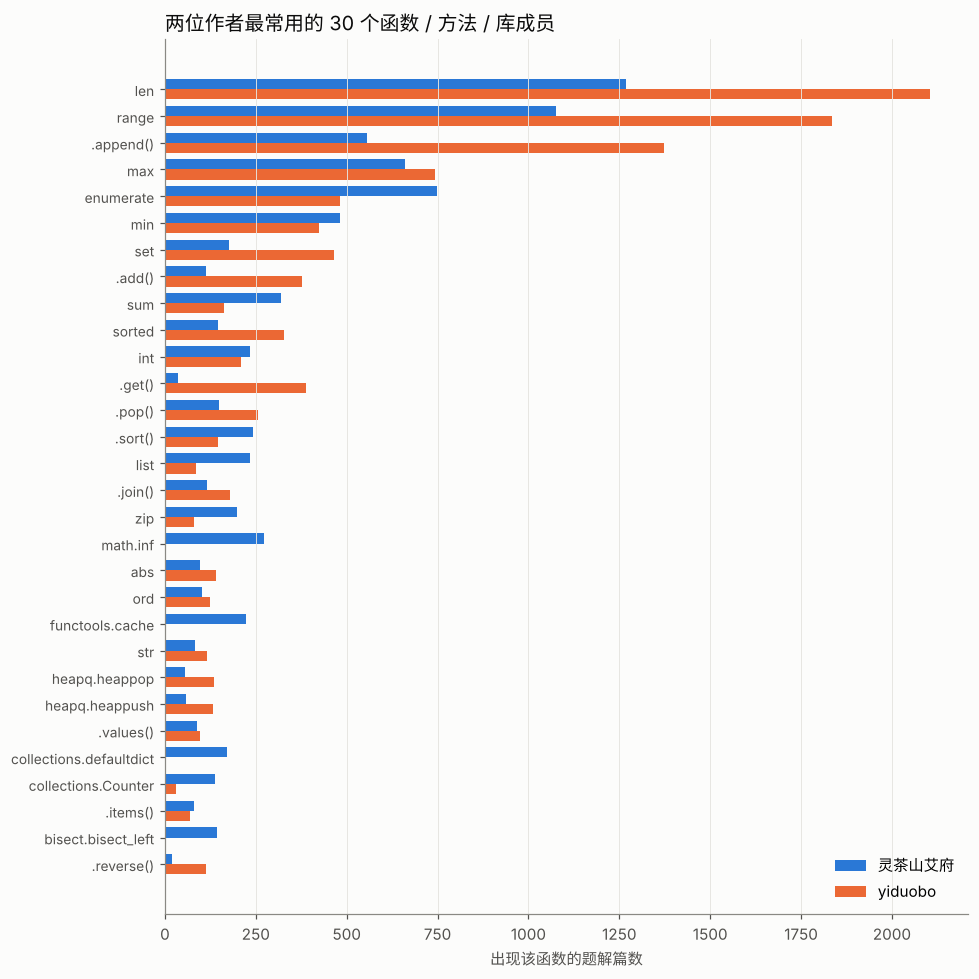

In [3]:
# 图 0-1：Top 30 函数，按作者分组的横向条形图
top = sorted(FUNC, key=lambda r: -(r[2] + r[3]))[:30][::-1]
names = [("." + r[0][1:] + "()") if r[1] == "method" else r[0] for r in top]
y = range(len(top))
fig, ax = plt.subplots(figsize=(9, 9))
h = 0.38
ax.barh([i + h / 2 for i in y], [r[2] for r in top], height=h, color=C_LING, label="灵茶山艾府")
ax.barh([i - h / 2 for i in y], [r[3] for r in top], height=h, color=C_YI, label="yiduobo")
ax.set_yticks(list(y)); ax.set_yticklabels(names, fontsize=9)
ax.set_xlabel("出现该函数的题解篇数")
ax.set_title("两位作者最常用的 30 个函数 / 方法 / 库成员", loc="left", fontsize=13, color=INK)
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", frameon=False)
plt.tight_layout(); plt.show()

In [4]:
# 只有一位作者使用的函数（≥5 篇）——风格差异一目了然
only_l = [r[0] for r in FUNC if r[2] >= 5 and r[3] == 0]
only_y = [r[0] for r in FUNC if r[3] >= 5 and r[2] == 0]
print("只有灵神用:", len(only_l), "个 →", ", ".join(only_l[:25]), "...")
print("只有 yiduobo 用:", only_y)

只有灵神用: 48 个 → math.inf, functools.cache, collections.defaultdict, bisect.bisect_left, .bit_length, map, itertools.pairwise, itertools.accumulate, .bit_count, all, pow, divmod, bisect.bisect_right, .count, math.isqrt, math.gcd, reversed, sortedcontainers.SortedList, string.ascii_lowercase, any, itertools.count, math.comb, functools.reduce, .cache_clear, .bisect_left ...
只有 yiduobo 用: ['copy.deepcopy', '.release', '.acquire', 'threading.Semaphore']


## 1. 内置函数

最常用的 `len / range / enumerate / zip / max / min / sum / sorted`。下面的单元格把每个函数的返回值都打印出来。

In [5]:
nums = [3, 1, 4, 1, 5, 9, 2, 6]
print("len      :", len(nums))
print("range    :", list(range(2, 10, 3)), "| 倒序:", list(range(4, -1, -1)))
print("enumerate:", list(enumerate("abc")))
print("zip      :", list(zip([1, 2, 3], "xyz")))
print("zip(*m)  :", list(zip(*[[1, 2, 3], [4, 5, 6]])), "← 转置")
print("max/min  :", max(nums), min(nums), "| key=len:", max(["ab", "abcd", "c"], key=len))
print("default  :", max([], default=-1))
print("sum      :", sum(nums), "| 布尔计数:", sum(x > 3 for x in nums))
print("sorted   :", sorted(nums), "| 原列表不变:", nums)
print("多关键字 :", sorted([[7, 0], [4, 4], [7, 1], [5, 0]], key=lambda p: (-p[0], p[1])))

len      : 8
range    : [2, 5, 8] | 倒序: [4, 3, 2, 1, 0]
enumerate: [(0, 'a'), (1, 'b'), (2, 'c')]
zip      : [(1, 'x'), (2, 'y'), (3, 'z')]
zip(*m)  : [(1, 4), (2, 5), (3, 6)] ← 转置
max/min  : 9 1 | key=len: abcd
default  : -1
sum      : 31 | 布尔计数: 4
sorted   : [1, 1, 2, 3, 4, 5, 6, 9] | 原列表不变: [3, 1, 4, 1, 5, 9, 2, 6]
多关键字 : [[7, 0], [7, 1], [5, 0], [4, 4]]


In [6]:
# 灵神 0001 两数之和：enumerate + 哈希表，打印每一步的哈希表状态
def two_sum(nums, target):
    idx = {}
    for j, x in enumerate(nums):
        print(f"j={j}, x={x}, 需要 {target - x}, 当前哈希表 {idx}")
        if target - x in idx:
            return [idx[target - x], j]
        idx[x] = j
print("答案:", two_sum([2, 7, 11, 15], 17))

j=0, x=2, 需要 15, 当前哈希表 {}
j=1, x=7, 需要 10, 当前哈希表 {2: 0}
j=2, x=11, 需要 6, 当前哈希表 {2: 0, 7: 1}
j=3, x=15, 需要 2, 当前哈希表 {2: 0, 7: 1, 11: 2}
答案: [0, 3]


In [7]:
# ord / chr：字母 ↔ 0..25；divmod：一维下标 ↔ 二维坐标
s = "leetcode"
cnt = [0] * 26
for c in s:
    cnt[ord(c) - ord("a")] += 1
print({chr(ord("a") + i): v for i, v in enumerate(cnt) if v})
n = 4                       # 4 列的网格
for k in [0, 5, 11]:
    r, c = divmod(k, n)
    print(f"下标 {k:2d} → 第 {r} 行第 {c} 列，反算 {r * n + c}")
print("pow(2, 100, 10**9+7) =", pow(2, 100, 10**9 + 7), "| 模逆元 pow(3, -1, 7) =", pow(3, -1, 7))

{'c': 1, 'd': 1, 'e': 3, 'l': 1, 'o': 1, 't': 1}
下标  0 → 第 0 行第 0 列，反算 0
下标  5 → 第 1 行第 1 列，反算 5
下标 11 → 第 2 行第 3 列，反算 11
pow(2, 100, 10**9+7) = 976371285 | 模逆元 pow(3, -1, 7) = 5


In [8]:
# all / any 的短路，以及 iter 判断子序列（灵神 0392）
def noisy(x):
    print("  检查", x); return x > 0
print("all ->", all(noisy(x) for x in [3, -1, 5]))   # 遇到 -1 立刻停
print("any ->", any(noisy(x) for x in [-2, 4, 6]))   # 遇到 4 立刻停
s, t = "ace", "abcde"
it = iter(t)
for c in s:
    print(f"  在剩余迭代器中找 {c!r}:", c in it)
print("next 找第一个偶数:", next((x for x in [1, 3, 8, 10] if x % 2 == 0), None))

  检查 3
  检查 -1
all -> False
  检查 -2
  检查 4
any -> True
  在剩余迭代器中找 'a': True
  在剩余迭代器中找 'c': True
  在剩余迭代器中找 'e': True
next 找第一个偶数: 8


## 2. 列表 / 字符串 / 字典 / 集合 的方法

用列表当**栈**：`append` 入栈、`pop` 出栈、`st[-1]` 看栈顶。下面用"有效的括号"（灵神 0020）逐步打印栈的变化。

In [9]:
def is_valid(s):
    mp = {")": "(", "]": "[", "}": "{"}
    st = []
    for c in s:
        if c not in mp:
            st.append(c)
            op = f"append({c!r})"
        elif not st or st.pop() != mp[c]:
            print(f"{c!r}: 不匹配 → False"); return False
        else:
            op = "pop()"
        print(f"{c!r}: {op:12s} 栈 = {st}")
    return not st
print(is_valid("([]{})"))

'(': append('(')  栈 = ['(']
'[': append('[')  栈 = ['(', '[']
']': pop()        栈 = ['(']
'{': append('{')  栈 = ['(', '{']
'}': pop()        栈 = ['(']
')': pop()        栈 = []
True


In [10]:
# 字符串方法：split / join / strip / replace / find / startswith
path = "/a/./b/../../c/"
parts = path.split("/")
print("split :", parts)
st = []
for p in parts:                       # 灵神 0071 简化路径
    if p == "..":
        if st: st.pop()
    elif p and p != ".":
        st.append(p)
print("简化后:", "/" + "/".join(st))
s = "  hello world  "
print(repr(s.strip()), s.find("o"), s.rfind("o"), s.find("z"))
print("leetcode".startswith("code", 4), "9669".replace("6", "9", 1), "101".zfill(8))

split : ['', 'a', '.', 'b', '..', '..', 'c', '']
简化后: /c
'hello world' 6 9 -1
True 9969 00000101


In [11]:
# 计数的三种写法：dict.get（yiduobo 风格）/ defaultdict / Counter（灵神风格）
from collections import defaultdict, Counter
words = ["a", "b", "a", "c", "a"]
d1 = {}
for w in words:
    d1[w] = d1.get(w, 0) + 1          # yiduobo 0030
d2 = defaultdict(int)
for w in words:
    d2[w] += 1                        # 灵神 0003
d3 = Counter(words)
print(d1, dict(d2), dict(d3), sep="\n")
print("三者相等:", d1 == dict(d2) == dict(d3))

{'a': 3, 'b': 1, 'c': 1}
{'a': 3, 'b': 1, 'c': 1}
{'a': 3, 'b': 1, 'c': 1}
三者相等: True


In [12]:
# 集合运算
a, b = {1, 2, 3, 4}, {3, 4, 5}
for expr in ["a & b", "a | b", "a - b", "a ^ b", "{1, 2} <= a", "a.isdisjoint({9})"]:
    print(f"{expr:18s} = {eval(expr)}")

a & b              = {3, 4}
a | b              = {1, 2, 3, 4, 5}
a - b              = {1, 2}
a ^ b              = {1, 2, 5}
{1, 2} <= a        = True
a.isdisjoint({9})  = True


## 3. collections

### Counter
`Counter` 是计数字典：不存在的 key 返回 0，`most_common(k)` 取出现最多的 k 个。下面统计一句话的字母频率并画成条形图。

most_common(5): [('t', 4), ('e', 4), ('o', 4), ('h', 3), ('a', 3)]
cnt['z'] = 1 | cnt['?'] = 0 （不存在返回 0）


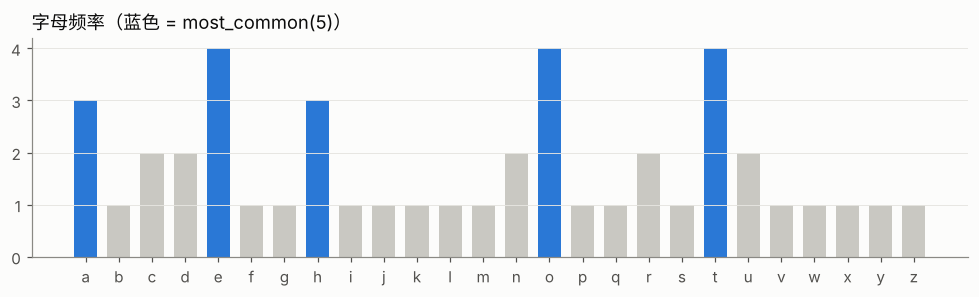

In [13]:
from collections import Counter
text = "the quick brown fox jumps over the lazy dog and the cat"
cnt = Counter(c for c in text if c.isalpha())
print("most_common(5):", cnt.most_common(5))
print("cnt['z'] =", cnt["z"], "| cnt['?'] =", cnt["?"], "（不存在返回 0）")
items = sorted(cnt.items())
fig, ax = plt.subplots(figsize=(9, 2.8))
top5 = {k for k, _ in cnt.most_common(5)}
ax.bar([k for k, _ in items], [v for _, v in items],
       color=[C_LING if k in top5 else "#c9c8c2" for k, _ in items], width=0.7)
ax.set_title("字母频率（蓝色 = most_common(5)）", loc="left", color=INK)
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

In [14]:
# Counter 运算：灵神 0299 猜数字游戏用 & 取交集次数
secret, guess = "1123", "0111"
a = sum(x == y for x, y in zip(secret, guess))
inter = Counter(secret) & Counter(guess)
print("Counter(secret) =", Counter(secret))
print("Counter(guess)  =", Counter(guess))
print("交集 &           =", inter, "→ total =", inter.total())
print(f"答案: {a}A{inter.total() - a}B")
print("加法:", Counter("aab") + Counter("abc"), "| 减法:", Counter("aab") - Counter("abc"))

Counter(secret) = Counter({'1': 2, '2': 1, '3': 1})
Counter(guess)  = Counter({'1': 3, '0': 1})
交集 &           = Counter({'1': 2}) → total = 2
答案: 1A1B
加法: Counter({'a': 3, 'b': 2, 'c': 1}) | 减法: Counter({'a': 1})


### deque：双端队列

两端 `append / appendleft / pop / popleft` 都是 O(1)。下面逐步执行一串操作，打印并画出每一步之后队列的样子。

append(1)          [1]
append(2)          [1, 2]
appendleft(0)      [0, 1, 2]
append(3)          [0, 1, 2, 3]
popleft() → 0      [1, 2, 3]
pop() → 3          [1, 2]
appendleft(9)      [9, 1, 2]
rotate(1)          [2, 9, 1]


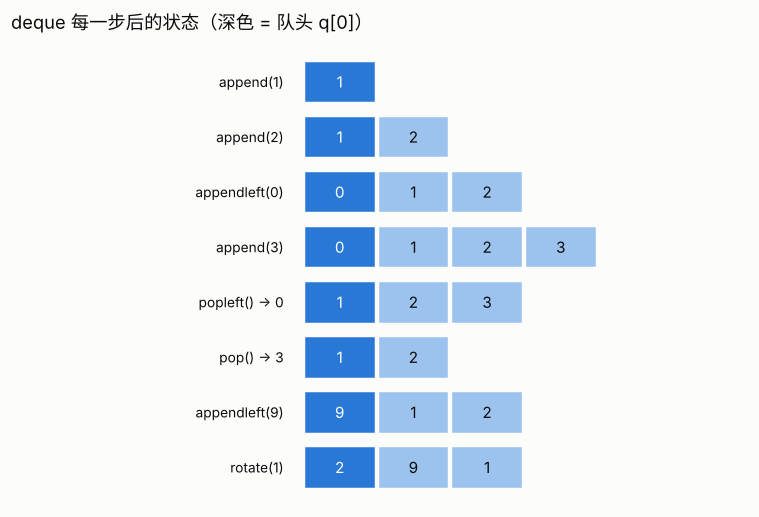

In [15]:
from collections import deque
ops = [("append", 1), ("append", 2), ("appendleft", 0), ("append", 3),
       ("popleft", None), ("pop", None), ("appendleft", 9), ("rotate", 1)]
q = deque()
states = []
for name, arg in ops:
    ret = getattr(q, name)(arg) if arg is not None else getattr(q, name)()
    label = f"{name}({'' if arg is None else arg})" + (f" → {ret}" if ret is not None else "")
    print(f"{label:18s} {list(q)}")
    states.append((label, list(q)))

fig, ax = plt.subplots(figsize=(7, 0.55 * len(states) + 0.4))
for row, (label, st) in enumerate(states):
    yy = len(states) - row
    ax.text(-0.3, yy, label, ha="right", va="center", fontsize=9, color=INK)
    for k, v in enumerate(st):
        ax.add_patch(plt.Rectangle((k, yy - 0.35), 0.92, 0.7, color=C_LING if k == 0 else "#9cc2ee"))
        ax.text(k + 0.46, yy, str(v), ha="center", va="center", color="white" if k == 0 else INK)
ax.set_xlim(-4, 6); ax.set_ylim(0.3, len(states) + 0.8); ax.axis("off")
ax.set_title("deque 每一步后的状态（深色 = 队头 q[0]）", loc="left", color=INK)
plt.tight_layout(); plt.show()

In [16]:
# BFS 层序遍历（灵神 0102）：用 deque 的 popleft，打印每一层
tree = {1: (2, 3), 2: (4, 5), 3: (None, 6), 4: (None, None), 5: (None, None), 6: (None, None)}
q, level = deque([1]), 0
while q:
    vals = []
    for _ in range(len(q)):
        node = q.popleft()
        vals.append(node)
        for ch in tree[node]:
            if ch is not None:
                q.append(ch)
    print(f"第 {level} 层: {vals}   队列剩余: {list(q)}")
    level += 1

第 0 层: [1]   队列剩余: [2, 3]
第 1 层: [2, 3]   队列剩余: [4, 5, 6]
第 2 层: [4, 5, 6]   队列剩余: []


In [17]:
# defaultdict 访问即插入 vs OrderedDict 实现 LRU（灵神 0146）
from collections import defaultdict, OrderedDict
g = defaultdict(list)
for u, v in [(0, 1), (0, 2), (1, 2)]:
    g[u].append(v); g[v].append(u)
print("邻接表:", dict(g))
_ = g[99]
print("访问 g[99] 之后 key 数量:", len(g), "← 只读查询请用 in / get")

class LRU:
    def __init__(self, cap): self.cap, self.c = cap, OrderedDict()
    def get(self, k):
        if k not in self.c: return -1
        self.c.move_to_end(k); return self.c[k]
    def put(self, k, v):
        self.c[k] = v; self.c.move_to_end(k)
        if len(self.c) > self.cap: self.c.popitem(last=False)
lru = LRU(2)
for op in [("put", 1, 1), ("put", 2, 2), ("get", 1), ("put", 3, 3), ("get", 2)]:
    r = getattr(lru, op[0])(*op[1:])
    print(f"{op[0]}{op[1:]} → {r}, 顺序(旧→新) {list(lru.c.items())}")

邻接表: {0: [1, 2], 1: [0, 2], 2: [0, 1]}
访问 g[99] 之后 key 数量: 4 ← 只读查询请用 in / get
put(1, 1) → None, 顺序(旧→新) [(1, 1)]
put(2, 2) → None, 顺序(旧→新) [(1, 1), (2, 2)]
get(1,) → 1, 顺序(旧→新) [(2, 2), (1, 1)]
put(3, 3) → None, 顺序(旧→新) [(1, 1), (3, 3)]
get(2,) → -1, 顺序(旧→新) [(1, 1), (3, 3)]


## 4. heapq：堆

`heapq` 把普通列表当最小堆：下标 `i` 的孩子是 `2i+1` 和 `2i+2`，任何父节点 ≤ 孩子，所以 `h[0]` 最小。下面写一个小工具把列表画成树，观察 push / pop 时堆的变化。

heappush(5) → 数组 [5]，堆顶 5
heappush(3) → 数组 [3, 5]，堆顶 3
heappush(8) → 数组 [3, 5, 8]，堆顶 3
heappush(1) → 数组 [1, 3, 8, 5]，堆顶 1
heappush(9) → 数组 [1, 3, 8, 5, 9]，堆顶 1
heappush(2) → 数组 [1, 3, 2, 5, 9, 8]，堆顶 1
heappop() = 1 → 数组 [2, 3, 8, 5, 9]
heappop() = 2 → 数组 [3, 5, 8, 9]


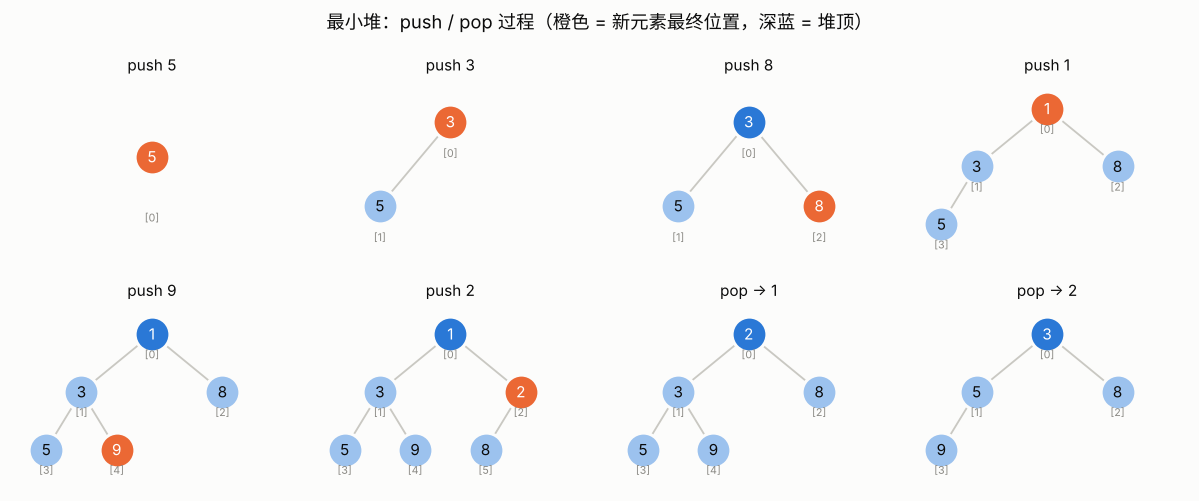

In [18]:
import math
from heapq import heapify, heappush, heappop, heapreplace, heappushpop, nlargest, nsmallest

def draw_heap(h, title, ax, hi=None):
    """把数组形式的堆画成二叉树；hi = 要高亮的下标"""
    ax.set_title(title, fontsize=10, color=INK); ax.axis("off")
    if not h: return
    depth = int(math.log2(len(h))) + 1
    pos = {}
    for i in range(len(h)):
        lv = int(math.log2(i + 1)); k = i - (2 ** lv - 1)
        pos[i] = ((k + 0.5) / 2 ** lv, depth - lv)
    for i in range(len(h)):
        for c in (2 * i + 1, 2 * i + 2):
            if c < len(h):
                ax.plot(*zip(pos[i], pos[c]), color="#c9c8c2", lw=1.2, zorder=1)
    for i, (x, y) in pos.items():
        col = C_YI if i == hi else (C_LING if i == 0 else "#9cc2ee")
        ax.scatter([x], [y], s=520, color=col, zorder=2, edgecolors="#fcfcfb", linewidths=2)
        ax.text(x, y, str(h[i]), ha="center", va="center", fontsize=10,
                color="white" if col != "#9cc2ee" else INK, zorder=3)
        ax.text(x, y - 0.42, f"[{i}]", ha="center", fontsize=7, color=MUTED)
    ax.set_xlim(0, 1); ax.set_ylim(0.3, depth + 0.5)

h = []
snap = []
for x in [5, 3, 8, 1, 9, 2]:
    heappush(h, x)
    print(f"heappush({x}) → 数组 {h}，堆顶 {h[0]}")
    snap.append((f"push {x}", h.copy(), h.index(x)))
for _ in range(2):
    v = heappop(h)
    print(f"heappop() = {v} → 数组 {h}")
    snap.append((f"pop → {v}", h.copy(), None))

fig, axes = plt.subplots(2, 4, figsize=(11, 4.6))
for ax, (t, hh, hi) in zip(axes.flat, snap):
    draw_heap(hh, t, ax, hi)
plt.suptitle("最小堆：push / pop 过程（橙色 = 新元素最终位置，深蓝 = 堆顶）", color=INK)
plt.tight_layout(); plt.show()

heapify      : [1, 4, 2, 9, 8, 7, 6] （不是有序数组，只满足堆性质）
heapreplace 0: 1 [0, 4, 2, 9, 8, 7, 6] ← 先弹旧堆顶，再放 0
heappushpop 0: 0 [1, 4, 2, 9, 8, 7, 6] ← 0 比堆顶小，直接返回 0，堆不变
nlargest(3)  : [9, 8, 7] | nsmallest(3): [1, 2, 4]


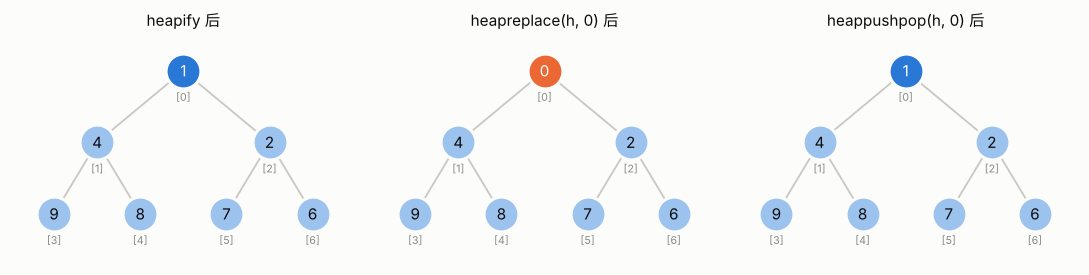

In [19]:
# heapify 一次建堆 O(n)；heapreplace / heappushpop 的区别
a = [9, 4, 7, 1, 8, 2, 6]
heapify(a)
print("heapify      :", a, "（不是有序数组，只满足堆性质）")
b = a.copy()
print("heapreplace 0:", heapreplace(b, 0), b, "← 先弹旧堆顶，再放 0")
c = a.copy()
print("heappushpop 0:", heappushpop(c, 0), c, "← 0 比堆顶小，直接返回 0，堆不变")
print("nlargest(3)  :", nlargest(3, a), "| nsmallest(3):", nsmallest(3, a))
fig, axes = plt.subplots(1, 3, figsize=(10, 2.6))
draw_heap(a, "heapify 后", axes[0]); draw_heap(b, "heapreplace(h, 0) 后", axes[1], 0)
draw_heap(c, "heappushpop(h, 0) 后", axes[2])
plt.tight_layout(); plt.show()

In [20]:
# 最大堆：存相反数（3.14 之前的通用写法）；以及元组堆（Dijkstra 风格）
h = []
for x in [3, 9, 4]:
    heappush(h, -x)
print("存负数:", h, "→ 最大值", -h[0])
try:
    from heapq import heappush_max, heappop_max   # Python 3.14+
    m = []
    for x in [3, 9, 4]: heappush_max(m, x)
    print("3.14 最大堆:", m, "→", heappop_max(m))
except ImportError:
    import sys
    print(f"当前 Python {sys.version_info.major}.{sys.version_info.minor} 没有 heappush_max，需 3.14+")

pq = [(0, "A")]
dist = {"A": 0}
graph = {"A": [("B", 4), ("C", 1)], "C": [("B", 2), ("D", 5)], "B": [("D", 1)], "D": []}
while pq:
    d, u = heappop(pq)
    if d > dist[u]: continue           # 延迟删除：过期的条目直接跳过
    print(f"弹出 ({d}, {u})，堆中剩余 {sorted(pq)}")
    for v, w in graph[u]:
        if d + w < dist.get(v, math.inf):
            dist[v] = d + w
            heappush(pq, (d + w, v))
print("最短路:", dist)

存负数: [-9, -3, -4] → 最大值 9
当前 Python 3.13 没有 heappush_max，需 3.14+
弹出 (0, A)，堆中剩余 []
弹出 (1, C)，堆中剩余 [(4, 'B')]
弹出 (3, B)，堆中剩余 [(4, 'B'), (6, 'D')]
弹出 (4, D)，堆中剩余 [(6, 'D')]
最短路: {'A': 0, 'B': 3, 'C': 1, 'D': 4}


## 5. bisect：二分查找

`bisect_left(a, x)` = 第一个 **≥ x** 的位置；`bisect_right(a, x)` = 第一个 **> x** 的位置。下图在数轴上标出两者的插入点。

x= 2: bisect_left=1, bisect_right=4, 等于 x 的个数=3
x= 6: bisect_left=5, bisect_right=5, 等于 x 的个数=0
x= 7: bisect_left=5, bisect_right=7, 等于 x 的个数=2
x= 0: bisect_left=0, bisect_right=0, 等于 x 的个数=0
x=10: bisect_left=8, bisect_right=8, 等于 x 的个数=0


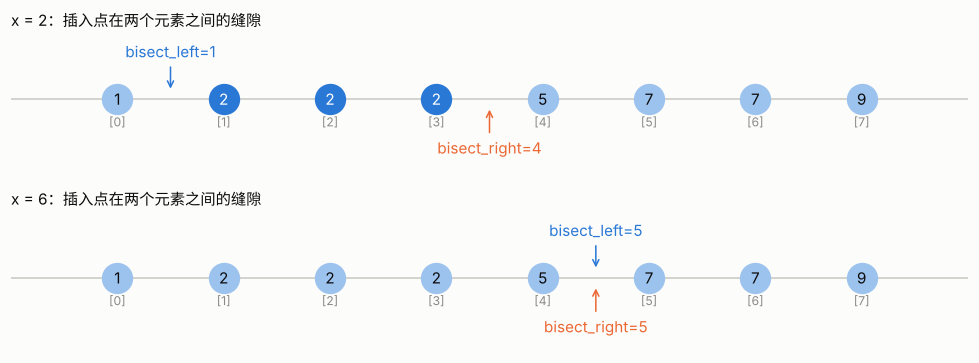

In [21]:
from bisect import bisect_left, bisect_right, insort
a = [1, 2, 2, 2, 5, 7, 7, 9]
for x in [2, 6, 7, 0, 10]:
    print(f"x={x:2d}: bisect_left={bisect_left(a, x)}, bisect_right={bisect_right(a, x)}, "
          f"等于 x 的个数={bisect_right(a, x) - bisect_left(a, x)}")

fig, axes = plt.subplots(2, 1, figsize=(9, 3.4))
for ax, x in zip(axes, [2, 6]):
    ax.axhline(0, color="#c9c8c2", lw=1)
    for i, v in enumerate(a):
        ax.scatter([i], [0], s=380, color=C_LING if v == x else "#9cc2ee", zorder=2)
        ax.text(i, 0, str(v), ha="center", va="center", color="white" if v == x else INK, zorder=3)
        ax.text(i, -0.55, f"[{i}]", ha="center", fontsize=8, color=MUTED)
    L_, R_ = bisect_left(a, x), bisect_right(a, x)
    ax.annotate(f"bisect_left={L_}", xy=(L_ - 0.5, 0.15), xytext=(L_ - 0.5, 0.85), ha="center",
                color=C_LING, arrowprops=dict(arrowstyle="->", color=C_LING))
    ax.annotate(f"bisect_right={R_}", xy=(R_ - 0.5, -0.15), xytext=(R_ - 0.5, -1.1), ha="center",
                color=C_YI, arrowprops=dict(arrowstyle="->", color=C_YI))
    ax.set_xlim(-1, len(a)); ax.set_ylim(-1.5, 1.3); ax.axis("off")
    ax.set_title(f"x = {x}：插入点在两个元素之间的缝隙", loc="left", fontsize=10, color=INK)
plt.tight_layout(); plt.show()

In [22]:
# 灵神招牌：二分答案 = bisect_left(range(...), True, key=check)
# 例：最小的整数 d，使 sum(ceil(x / d)) <= threshold（灵神 1283）
nums, threshold = [1, 2, 5, 9], 6
def check(d):
    return sum((x + d - 1) // d for x in nums) <= threshold
print("候选 d :", list(range(1, 11)))
print("check  :", [int(check(d)) for d in range(1, 11)], "← 单调：一串 0 后面全是 1")
ans = bisect_left(range(max(nums) + 1), True, 1, key=check)
print("第一个 True 的位置 =", ans)

# 手写二分（yiduobo 风格，mid = (l + r) >> 1），打印每一步
l, r = 1, max(nums)
while l < r:
    mid = (l + r) >> 1
    print(f"  l={l}, r={r}, mid={mid}, check={check(mid)}")
    if check(mid): r = mid
    else: l = mid + 1
print("手写二分结果 =", l)

候选 d : [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
check  : [0, 0, 0, 0, 1, 1, 1, 1, 1, 1] ← 单调：一串 0 后面全是 1
第一个 True 的位置 = 5
  l=1, r=9, mid=5, check=True
  l=1, r=5, mid=3, check=False
  l=4, r=5, mid=4, check=False
手写二分结果 = 5


In [23]:
# LIS 的贪心 + 二分（0300）：g[i] = 长度为 i+1 的递增子序列的最小结尾
nums = [10, 9, 2, 5, 3, 7, 101, 18]
g = []
for x in nums:
    j = bisect_left(g, x)
    if j == len(g): g.append(x); act = "append"
    else: g[j] = x; act = f"g[{j}] = {x}"
    print(f"x={x:3d}: {act:12s} g = {g}")
print("LIS 长度 =", len(g))
a = [1, 4, 6]; insort(a, 5); print("insort:", a)
try:
    from sortedcontainers import SortedList
    sl = SortedList([5, 1, 3]); sl.add(4)
    print("SortedList:", list(sl), "| sl[0], sl[-1] =", sl[0], sl[-1], "| bisect_left(4) =", sl.bisect_left(4))
except ImportError:
    print("未安装 sortedcontainers（pip install sortedcontainers），跳过 SortedList 演示")

x= 10: append       g = [10]
x=  9: g[0] = 9     g = [9]
x=  2: g[0] = 2     g = [2]
x=  5: append       g = [2, 5]
x=  3: g[1] = 3     g = [2, 3]
x=  7: append       g = [2, 3, 7]
x=101: append       g = [2, 3, 7, 101]
x= 18: g[3] = 18    g = [2, 3, 7, 18]
LIS 长度 = 4
insort: [1, 4, 5, 6]
SortedList: [1, 3, 4, 5] | sl[0], sl[-1] = 1 5 | bisect_left(4) = 2


## 6. itertools

### accumulate：前缀和
`s = list(accumulate(nums, initial=0))` 后，子数组 `nums[l..r]` 的和是 `s[r+1] - s[l]`。下图上半部分是原数组，下半部分是前缀和，红框是 `s[r+1] - s[l]` 的两端。

nums          : [3, -1, 4, 1, -5, 9, 2]
前缀和 s       : [0, 3, 2, 6, 7, 2, 11, 13]
前缀最大值     : [3, 3, 4, 4, 4, 9, 9]
前缀异或       : [0, 3, -4, -8, -7]
sum(nums[2..5]) = s[6] - s[2] = 11 - 2 = 9，直接求和 = 9


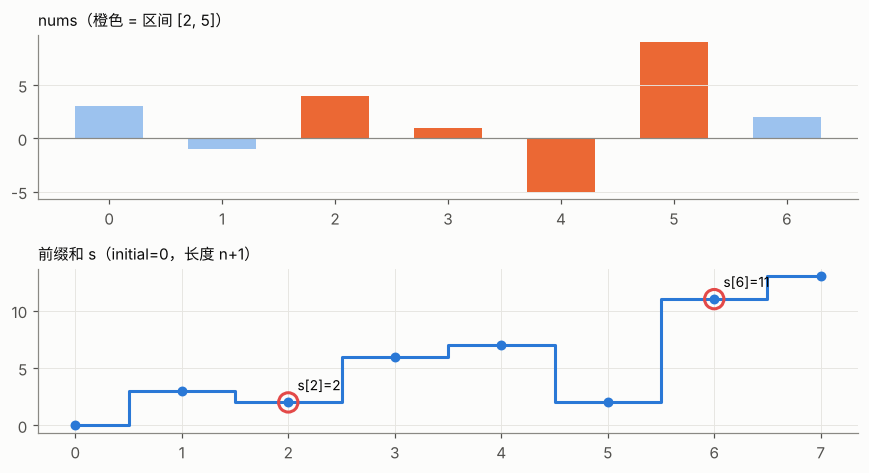

In [24]:
from itertools import accumulate, pairwise, permutations, combinations, product, groupby, count, chain, zip_longest
from operator import xor
nums = [3, -1, 4, 1, -5, 9, 2]
s = list(accumulate(nums, initial=0))
print("nums          :", nums)
print("前缀和 s       :", s)
print("前缀最大值     :", list(accumulate(nums, max)))
print("前缀异或       :", list(accumulate(nums[:4], xor, initial=0)))
l, r = 2, 5
print(f"sum(nums[{l}..{r}]) = s[{r + 1}] - s[{l}] = {s[r + 1]} - {s[l]} = {s[r + 1] - s[l]}，直接求和 = {sum(nums[l:r + 1])}")

fig, (a1, a2) = plt.subplots(2, 1, figsize=(8, 4.4), sharex=False)
a1.bar(range(len(nums)), nums, color=[C_YI if l <= i <= r else "#9cc2ee" for i in range(len(nums))], width=0.6)
a1.axhline(0, color=MUTED, lw=0.8); a1.set_title(f"nums（橙色 = 区间 [{l}, {r}]）", loc="left", fontsize=10, color=INK)
a1.set_xticks(range(len(nums))); a1.grid(axis="x", visible=False)
a2.step(range(len(s)), s, where="mid", color=C_LING, lw=2)
a2.scatter(range(len(s)), s, color=C_LING, s=30, zorder=3)
for i in (l, r + 1):
    a2.scatter([i], [s[i]], s=160, facecolors="none", edgecolors="#e34948", linewidths=2, zorder=4)
    a2.annotate(f"s[{i}]={s[i]}", (i, s[i]), textcoords="offset points", xytext=(6, 8), fontsize=9)
a2.set_xticks(range(len(s))); a2.set_title("前缀和 s（initial=0，长度 n+1）", loc="left", fontsize=10, color=INK)
plt.tight_layout(); plt.show()

In [25]:
print("pairwise         :", list(pairwise([1, 3, 6, 10])), "→ 相邻差", [y - x for x, y in pairwise([1, 3, 6, 10])])
print("permutations(3,2):", list(permutations("abc", 2)))
print("combinations(4,2):", list(combinations(range(4), 2)))
print("product(repeat=2):", [p for p in product((-1, 0, 1), repeat=2) if any(p)], "← 八方向")
print("groupby (RLE)    :", [(k, len(list(g))) for k, g in groupby("aaabccdddd")])
print("chain            :", list(chain([1], (2, 3), "ab")), "| from_iterable:", list(chain.from_iterable([[1], [2, 3]])))
print("zip_longest      :", list(zip_longest([1, 2, 3], [9], fillvalue=0)))
for i in count(1):
    if i * i > 30: break
print("count: 第一个平方 > 30 的 i =", i)

pairwise         : [(1, 3), (3, 6), (6, 10)] → 相邻差 [2, 3, 4]
permutations(3,2): [('a', 'b'), ('a', 'c'), ('b', 'a'), ('b', 'c'), ('c', 'a'), ('c', 'b')]
combinations(4,2): [(0, 1), (0, 2), (0, 3), (1, 2), (1, 3), (2, 3)]
product(repeat=2): [(-1, -1), (-1, 0), (-1, 1), (0, -1), (0, 1), (1, -1), (1, 0), (1, 1)] ← 八方向
groupby (RLE)    : [('a', 3), ('b', 1), ('c', 2), ('d', 4)]
chain            : [1, 2, 3, 'a', 'b'] | from_iterable: [1, 2, 3]
zip_longest      : [(1, 9), (2, 0), (3, 0)]
count: 第一个平方 > 30 的 i = 6


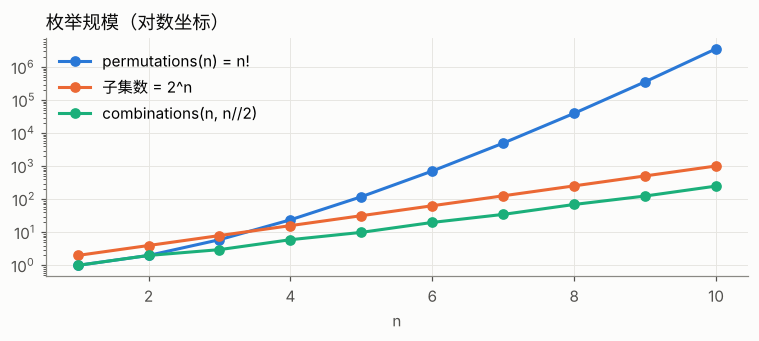

In [26]:
# 排列组合数量增长（为什么只有 n 很小时才能直接枚举）
import math
ns = list(range(1, 11))
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(ns, [math.factorial(n) for n in ns], marker="o", color=C_LING, lw=2, label="permutations(n) = n!")
ax.plot(ns, [2 ** n for n in ns], marker="o", color=C_YI, lw=2, label="子集数 = 2^n")
ax.plot(ns, [math.comb(n, n // 2) for n in ns], marker="o", color="#1baf7a", lw=2, label="combinations(n, n//2)")
ax.set_yscale("log"); ax.set_xlabel("n"); ax.set_title("枚举规模（对数坐标）", loc="left", color=INK)
ax.legend(frameon=False); plt.tight_layout(); plt.show()

## 7. functools：@cache 记忆化

同样的斐波那契递归，加不加 `@cache` 调用次数天差地别：不加是指数级 ≈ φⁿ，加了每个 n 只算一次。

fib( 5): 不加 cache 调用      15 次，加 @cache 调用  6 次
fib(10): 不加 cache 调用     177 次，加 @cache 调用 11 次
fib(20): 不加 cache 调用   21891 次，加 @cache 调用 21 次
fib(25): 不加 cache 调用  242785 次，加 @cache 调用 26 次


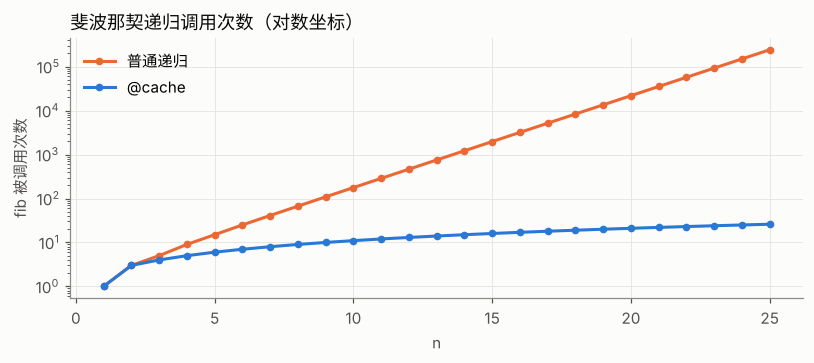

In [27]:
from functools import cache, lru_cache, reduce, cmp_to_key

def count_calls(n, cached):
    calls = 0
    def fib(k):
        nonlocal calls
        calls += 1
        return k if k < 2 else fib(k - 1) + fib(k - 2)
    if cached:
        fib = cache(fib)          # 等价于在 def 上写 @cache
    fib(n)
    return calls

ns = list(range(1, 26))
plain = [count_calls(n, False) for n in ns]
memo = [count_calls(n, True) for n in ns]
for n in (5, 10, 20, 25):
    print(f"fib({n:2d}): 不加 cache 调用 {plain[n - 1]:>7} 次，加 @cache 调用 {memo[n - 1]:>2} 次")

fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.plot(ns, plain, color=C_YI, lw=2, marker="o", markersize=4, label="普通递归")
ax.plot(ns, memo, color=C_LING, lw=2, marker="o", markersize=4, label="@cache")
ax.set_yscale("log"); ax.set_xlabel("n"); ax.set_ylabel("fib 被调用次数")
ax.set_title("斐波那契递归调用次数（对数坐标）", loc="left", color=INK)
ax.legend(frameon=False); plt.tight_layout(); plt.show()

In [28]:
# 灵神 0062 不同路径：记忆化搜索 → 查看缓存信息 → cache_clear
@cache
def dfs(i, j):
    if i < 0 or j < 0: return 0
    if i == 0 and j == 0: return 1
    return dfs(i - 1, j) + dfs(i, j - 1)
print("uniquePaths(3, 7) =", dfs(2, 6))
print("cache_info:", dfs.cache_info())
dfs.cache_clear()                      # 灵神 1690：防止爆内存
print("清空后   :", dfs.cache_info())

# yiduobo 风格：手写 memo 字典（Python 2 没有 @cache）
memo = {}
def dfs2(i, j):
    if i < 0 or j < 0: return 0
    if i == 0 and j == 0: return 1
    if (i, j) not in memo:
        memo[(i, j)] = dfs2(i - 1, j) + dfs2(i, j - 1)
    return memo[(i, j)]
print("手写 memo:", dfs2(2, 6), "| memo 大小", len(memo))

uniquePaths(3, 7) = 28
cache_info: CacheInfo(hits=12, misses=29, maxsize=None, currsize=29)
清空后   : CacheInfo(hits=0, misses=0, maxsize=None, currsize=0)
手写 memo: 28 | memo 大小 20


In [29]:
# reduce 与 cmp_to_key
from operator import xor, mul
print("reduce(xor, [4,1,2,1,2]) =", reduce(xor, [4, 1, 2, 1, 2]), "← 灵神 0136")
print("reduce(mul, 1..5)        =", reduce(mul, range(1, 6)))
steps = []
reduce(lambda acc, x: steps.append((acc, x)) or acc + x, [1, 2, 3, 4])
print("reduce 折叠过程 (acc, x)  :", steps)
nums = ["3", "30", "34", "5", "9"]
nums.sort(key=cmp_to_key(lambda a, b: int(b + a) - int(a + b)))
print("最大数（灵神 0179）       :", "".join(nums))

reduce(xor, [4,1,2,1,2]) = 4 ← 灵神 0136
reduce(mul, 1..5)        = 120
reduce 折叠过程 (acc, x)  : [(1, 2), (3, 3), (6, 4)]
最大数（灵神 0179）       : 9534330


## 8. math / 位运算

### // 和 % 遇到负数
Python 的 `//` 向下取整、`%` 结果与除数同号；C++/Java 是向 0 截断。

In [30]:
print(f"{'a':>4} {'b':>3} | {'a//b':>5} {'a%b':>4} | {'int(a/b)':>8} | 恒等式 a == (a//b)*b + a%b")
for a, b in [(7, 2), (-7, 2), (7, -2), (-7, -2)]:
    print(f"{a:>4} {b:>3} | {a // b:>5} {a % b:>4} | {int(a / b):>8} | {a == (a // b) * b + a % b}")
MOD = 1_000_000_007
print("(3 - 5) % MOD =", (3 - 5) % MOD, "← 自动非负")
from math import inf, gcd, lcm, isqrt, sqrt, comb, ceil
print("inf:", inf > 10 ** 100, "| gcd/lcm:", gcd(12, 18), lcm(4, 6), "| comb(5,2):", comb(5, 2))
m = (10 ** 15 + 1) ** 2 - 1
print("isqrt 精确:", isqrt(m) == 10 ** 15, "| int(sqrt) 出错:", int(sqrt(m)) == 10 ** 15)
print("整数上取整:", ceil(7 / 2), (7 + 2 - 1) // 2, -(-7 // 2))

   a   b |  a//b  a%b | int(a/b) | 恒等式 a == (a//b)*b + a%b
   7   2 |     3    1 |        3 | True
  -7   2 |    -4    1 |       -3 | True
   7  -2 |    -4   -1 |       -3 | True
  -7  -2 |     3   -1 |        3 | True
(3 - 5) % MOD = 1000000005 ← 自动非负
inf: True | gcd/lcm: 6 12 | comb(5,2): 10
isqrt 精确: True | int(sqrt) 出错: False
整数上取整: 4 4 4


### 位运算逐位展示

把一个数和几种常见位操作的结果按二进制对齐打印。

In [31]:
x = 0b101100
rows = [("x", x), ("x - 1", x - 1), ("x & (x-1) 去掉最低位1", x & (x - 1)),
        ("-x（补码）", -x & 0xFF), ("x & -x  lowbit", x & -x), ("x | 1<<0 置位", x | 1),
        ("x ^ 1<<3 翻转第3位", x ^ (1 << 3)), ("x >> 2", x >> 2), ("x << 1", x << 1)]
for name, v in rows:
    print(f"{name:24s} {v:08b}  ({v})")
print("bit_length:", x.bit_length(), "| bit_count:", x.bit_count(), "| ~x =", ~x, "= -x-1")

x                        00101100  (44)
x - 1                    00101011  (43)
x & (x-1) 去掉最低位1         00101000  (40)
-x（补码）                   11010100  (212)
x & -x  lowbit           00000100  (4)
x | 1<<0 置位              00101101  (45)
x ^ 1<<3 翻转第3位           00100100  (36)
x >> 2                   00001011  (11)
x << 1                   01011000  (88)
bit_length: 6 | bit_count: 3 | ~x = -45 = -x-1


mask= 0 = 0000 → []
mask= 1 = 0001 → ['a']
mask= 2 = 0010 → ['b']
mask= 3 = 0011 → ['a', 'b']
mask= 4 = 0100 → ['c']
mask= 5 = 0101 → ['a', 'c']
...共 16 个子集


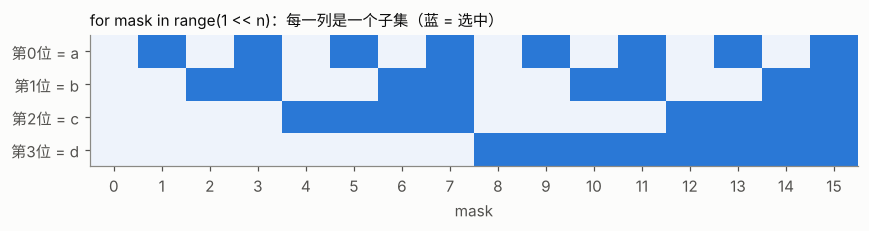

In [32]:
# 枚举子集（灵神 0078），画成 0/1 矩阵
nums = ["a", "b", "c", "d"]
n = len(nums)
masks = list(range(1 << n))
for mask in masks[:6]:
    print(f"mask={mask:2d} = {mask:04b} → {[nums[i] for i in range(n) if mask >> i & 1]}")
print("...共", len(masks), "个子集")
fig, ax = plt.subplots(figsize=(8, 2.2))
grid = [[mask >> i & 1 for mask in masks] for i in range(n)]
ax.imshow(grid, cmap=matplotlib.colors.ListedColormap(["#eef3fb", C_LING]), aspect="auto")
ax.set_yticks(range(n)); ax.set_yticklabels([f"第{i}位 = {nums[i]}" for i in range(n)])
ax.set_xticks(masks); ax.set_xlabel("mask"); ax.grid(False)
ax.set_title("for mask in range(1 << n)：每一列是一个子集（蓝 = 选中）", loc="left", fontsize=10, color=INK)
plt.tight_layout(); plt.show()

In [33]:
# 树状数组：i += i & -i（灵神 0307 / yiduobo 0307 一字不差）
n = 16
i = 3
path = []
while i <= n:
    path.append(i); i += i & -i
print("update(3) 依次修改的下标:", path, [f"{p:05b}" for p in path])
i, path = 13, []
while i > 0:
    path.append(i); i -= i & -i
print("query(13) 依次累加的下标:", path, [f"{p:04b}" for p in path])

update(3) 依次修改的下标: [3, 4, 8, 16] ['00011', '00100', '01000', '10000']
query(13) 依次累加的下标: [13, 12, 8] ['1101', '1100', '1000']


## 9. 语法特性与惯用法

先看普查：两位作者在语法上的差异比函数上的更大。

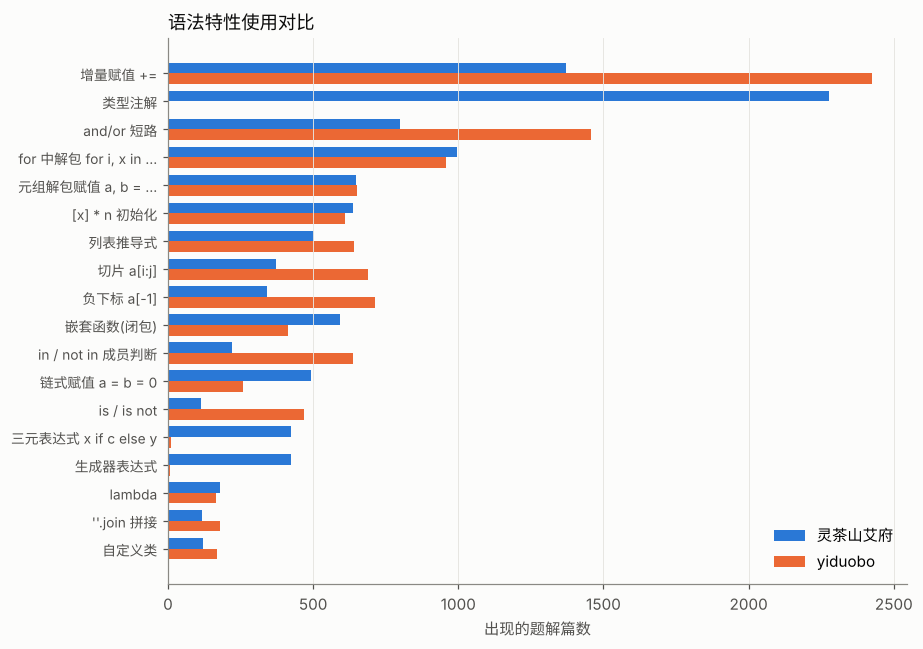

三元表达式 x if c else y  灵神  423 篇  yiduobo   12 篇
生成器表达式               灵神  425 篇  yiduobo    8 篇
nonlocal             灵神  109 篇  yiduobo    0 篇
global               灵神    1 篇  yiduobo   47 篇
海象运算符 :=             灵神   15 篇  yiduobo    0 篇


In [34]:
syn = [r for r in SYN if r[1] == "syn" and r[2] + r[3] >= 20]
syn = sorted(syn, key=lambda r: r[2] + r[3])[-18:]
fig, ax = plt.subplots(figsize=(8.5, 6))
yy = range(len(syn)); h = 0.38
ax.barh([i + h / 2 for i in yy], [r[2] for r in syn], height=h, color=C_LING, label="灵茶山艾府")
ax.barh([i - h / 2 for i in yy], [r[3] for r in syn], height=h, color=C_YI, label="yiduobo")
ax.set_yticks(list(yy)); ax.set_yticklabels([r[0] for r in syn], fontsize=9)
ax.set_xlabel("出现的题解篇数"); ax.grid(axis="y", visible=False)
ax.set_title("语法特性使用对比", loc="left", color=INK); ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()
for name in ["三元表达式 x if c else y", "生成器表达式", "nonlocal", "global", "海象运算符 :="]:
    r = next(r for r in SYN if r[0] == name)
    print(f"{name:20s} 灵神 {r[2]:4d} 篇  yiduobo {r[3]:4d} 篇")

In [35]:
# 推导式 & 二维初始化陷阱
print([x * x for x in range(6) if x % 2 == 0])
print({x: i for i, x in enumerate("abc")})
bad = [[0] * 3] * 2
good = [[0] * 3 for _ in range(2)]
bad[0][0] = good[0][0] = 1
print("[[0]*3]*2 修改后      :", bad, "← 两行是同一个对象", bad[0] is bad[1])
print("推导式初始化 修改后   :", good, bad[0] is good[0])

[0, 4, 16]
{'a': 0, 'b': 1, 'c': 2}
[[0]*3]*2 修改后      : [[1, 0, 0], [1, 0, 0]] ← 两行是同一个对象 True
推导式初始化 修改后   : [[1, 0, 0], [0, 0, 0]] False


In [36]:
# 切片可视化
a = list(range(10))
for expr in ["a[2:5]", "a[:3]", "a[-3:]", "a[::2]", "a[::-1]", "a[7:2:-2]", "a[20:]"]:
    print(f"{expr:10s} → {eval(expr)}")
s = "racecar"; print("回文:", s == s[::-1])
nums = [3, 1, 3, 2]; alias = nums
nums[:] = sorted(set(nums))          # 灵神 0026：原地替换，外部引用也能看到
print("nums[:] = ... 后 alias =", alias)

a[2:5]     → [2, 3, 4]
a[:3]      → [0, 1, 2]
a[-3:]     → [7, 8, 9]
a[::2]     → [0, 2, 4, 6, 8]
a[::-1]    → [9, 8, 7, 6, 5, 4, 3, 2, 1, 0]
a[7:2:-2]  → [7, 5, 3]
a[20:]     → []
回文: True
nums[:] = ... 后 alias = [1, 2, 3]


In [37]:
# 解包 / 交换 / 滚动变量
f0, f1 = 0, 1
for k in range(8):
    f0, f1 = f1, f0 + f1
    print(f"k={k}: f0={f0}, f1={f1}")
first, *rest = [1, 2, 3, 4]; print("星号解包:", first, rest)
print("zip(*grid) 转置:", list(zip(*[[1, 2, 3], [4, 5, 6]])))

k=0: f0=1, f1=1
k=1: f0=1, f1=2
k=2: f0=2, f1=3
k=3: f0=3, f1=5
k=4: f0=5, f1=8
k=5: f0=8, f1=13
k=6: f0=13, f1=21
k=7: f0=21, f1=34
星号解包: 1 [2, 3, 4]
zip(*grid) 转置: [(1, 4), (2, 5), (3, 6)]


In [38]:
# nonlocal：嵌套 dfs 修改外层 ans（灵神 0543 二叉树直径）
tree = {1: (2, 3), 2: (4, 5), 3: (None, None), 4: (None, None), 5: (None, None)}
def diameter(root):
    ans = 0
    def dfs(node):
        nonlocal ans
        if node is None: return -1
        l, r = dfs(tree[node][0]), dfs(tree[node][1])
        ans = max(ans, l + r + 2)
        print(f"  节点 {node}: 左链 {l + 1}, 右链 {r + 1}, 经过它的路径 {l + r + 2}, ans={ans}")
        return max(l, r) + 1
    dfs(root)
    return ans
print("直径 =", diameter(1))

def broken():
    cnt = 0
    def inc():
        cnt += 1            # 没写 nonlocal
    try: inc()
    except UnboundLocalError as e: print("不写 nonlocal →", type(e).__name__)
broken()

  节点 4: 左链 0, 右链 0, 经过它的路径 0, ans=0
  节点 5: 左链 0, 右链 0, 经过它的路径 0, ans=0
  节点 2: 左链 1, 右链 1, 经过它的路径 2, ans=2
  节点 3: 左链 0, 右链 0, 经过它的路径 0, ans=2
  节点 1: 左链 2, 右链 1, 经过它的路径 3, ans=3
直径 = 3
不写 nonlocal → UnboundLocalError


In [39]:
# 海象运算符、链式比较、三元表达式、lambda + key
n, i, s0 = 20, 1, 0
while (t := s0 + i * i) <= n:
    print(f"i={i}, t={t}"); i += 1
x, m, nn = 3, 5, 5
print("0 <= x < m and 0 <= x < nn:", 0 <= x < m and 0 <= x < nn)
print(["odd" if v % 2 else "even" for v in range(4)])
envelopes = [[5, 4], [6, 4], [6, 7], [2, 3]]
envelopes.sort(key=lambda e: (e[0], -e[1]))          # 灵神 0354
print("宽升序、高降序:", envelopes)

i=1, t=1
i=2, t=4
i=3, t=9
i=4, t=16
0 <= x < m and 0 <= x < nn: True
['even', 'odd', 'even', 'odd']
宽升序、高降序: [[2, 3], [5, 4], [6, 7], [6, 4]]


## 10. Python 2 vs 3

yiduobo 有约 3600 篇是 Python 2 写法。最容易踩的坑：**整数 `/`**。下表对比同一表达式在 Python 2 和 Python 3 中的结果（Python 2 结果按其规则模拟）。

In [40]:
def py2_div(a, b):                      # Python 2 中 int / int 是向下取整
    return a // b if isinstance(a, int) and isinstance(b, int) else a / b
exprs = [("(3 + 4 + 1) / 2", 3 + 4 + 1, 2), ("7 / 2", 7, 2), ("-7 / 2", -7, 2), ("7.0 / 2", 7.0, 2)]
print(f"{'表达式':16s} {'Python 2':>9} {'Python 3':>9}   Python 3 正确写法")
for e, a, b in exprs:
    print(f"{e:16s} {py2_div(a, b)!s:>9} {a / b!s:>9}   {e.replace(' / ', ' // ') if isinstance(a, int) else e}")
try:
    [1, 2, 3][4 / 2]
except TypeError as err:
    print("用 / 的结果当下标 →", type(err).__name__, ":", err)

r = next(r for r in SYN if r[0] == "/")
print(f"\n普查：使用 / 的题解 —— 灵神 {r[2]} 篇（真·浮点除法），yiduobo {r[3]} 篇（大多是 Py2 整除）")

表达式               Python 2  Python 3   Python 3 正确写法
(3 + 4 + 1) / 2          4       4.0   (3 + 4 + 1) // 2
7 / 2                    3       3.5   7 // 2
-7 / 2                  -4      -3.5   -7 // 2
7.0 / 2                3.5       3.5   7.0 / 2
用 / 的结果当下标 → TypeError : list indices must be integers or slices, not float

普查：使用 / 的题解 —— 灵神 42 篇（真·浮点除法），yiduobo 546 篇（大多是 Py2 整除）


In [41]:
# 其他差异：map/zip 返回迭代器、dict 视图、round、print
m = map(int, "123")
print("map 第一次:", list(m), "第二次:", list(m))
d = {"a": 1, "b": 2}
print("d.keys():", d.keys(), "| 需要列表时 list(d) =", list(d))
print("round(2.5) =", round(2.5), "（Py2 为 3.0）| round(3.5) =", round(3.5))
for row in [r for r in SYN if r[1] == "py2"]:
    print(f"Py2 特征 {row[0]:24s} 灵神 {row[2]:4d} 篇  yiduobo {row[3]:4d} 篇")

map 第一次: [1, 2, 3] 第二次: []
d.keys(): dict_keys(['a', 'b']) | 需要列表时 list(d) = ['a', 'b']
round(2.5) = 2 （Py2 为 3.0）| round(3.5) = 4
Py2 特征 docstring 类型注释 :type     灵神    0 篇  yiduobo 3622 篇
Py2 特征 class X(object)          灵神    1 篇  yiduobo 3618 篇
Py2 特征 需修复才能用 py3 解析            灵神    0 篇  yiduobo   15 篇
Py2 特征 print 语句                 灵神    0 篇  yiduobo   14 篇
Py2 特征 sort/sorted 的 cmp= 参数    灵神    0 篇  yiduobo    1 篇


## 11. 速查

| 场景 | 灵神写法（Python 3） | yiduobo 写法（Python 2） |
|---|---|---|
| 计数 | `Counter(a)` / `defaultdict(int)` | `d[k] = d.get(k, 0) + 1` |
| 无穷 | `inf` | `10 ** 9` / `10 ** 18` |
| 记忆化 | `@cache` | 手写 dict 或递推 |
| 前缀和 | `list(accumulate(a, initial=0))` | 手写循环 |
| 二分答案 | `bisect_left(range(hi), True, lo, key=check)` | `while l < r: mid = (l + r) >> 1` |
| 相邻元素 | `for x, y in pairwise(a)` | `for i in range(1, n)` |
| 外层变量 | `nonlocal ans` | `self.res` / `global` |
| 整除 | `a // b` | `a / b` |
| 最大堆 | `heappush_max`（3.14）或存负数 | 存负数 |

内置函数     灵神用过  29 个，yiduobo 用过  19 个
内置类型方法   灵神用过  39 个，yiduobo 用过  28 个
标准库成员    灵神用过  46 个，yiduobo 用过  12 个


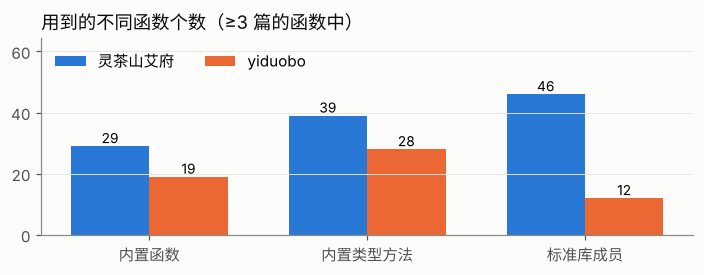

In [42]:
# 按类别汇总：每个类别里各作者用到了多少个不同的函数
from collections import defaultdict
cat_name = {"builtin": "内置函数", "method": "内置类型方法", "mod": "标准库成员"}
agg = defaultdict(lambda: [0, 0])
for name, cat, l, y, *_ in FUNC:
    agg[cat][0] += l > 0; agg[cat][1] += y > 0
for cat, (l, y) in agg.items():
    print(f"{cat_name[cat]:8s} 灵神用过 {l:3d} 个，yiduobo 用过 {y:3d} 个")
fig, ax = plt.subplots(figsize=(6.5, 2.6))
cats = list(agg)
xs = range(len(cats)); w = 0.36
ax.bar([i - w / 2 for i in xs], [agg[c][0] for c in cats], width=w, color=C_LING, label="灵茶山艾府")
ax.bar([i + w / 2 for i in xs], [agg[c][1] for c in cats], width=w, color=C_YI, label="yiduobo")
for i, c in enumerate(cats):
    ax.text(i - w / 2, agg[c][0] + 1, agg[c][0], ha="center", fontsize=9)
    ax.text(i + w / 2, agg[c][1] + 1, agg[c][1], ha="center", fontsize=9)
ax.set_xticks(list(xs)); ax.set_xticklabels([cat_name[c] for c in cats]); ax.grid(axis="x", visible=False)
ax.set_ylim(0, max(max(v) for v in agg.values()) * 1.4)
ax.set_title("用到的不同函数个数（≥3 篇的函数中）", loc="left", color=INK); ax.legend(frameon=False, ncol=2, loc="upper left")
plt.tight_layout(); plt.show()